🎨 RGB Image Inspector & Color Analyzer

In [ ]:
# Step 1: Import required libraries & verify environment
import sys
import os
import io
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, HTML

# Check if running in Google Colab
IN_COLAB = 'google.colab' in sys.modules
print(f"Environment: {'Google Colab' if IN_COLAB else 'Local Jupyter / Python'}")
print("NumPy version:", np.__version__)


Environment: Google Colab
NumPy version: 2.1.3


In [ ]:
def launch_interactive_inspector():
    """Renders a self-contained, fully interactive RGB Image Inspector inside the notebook cell."""
    html_code = """
    <div id="inspector-root" style="font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; background: #1a1b23; color: #f0f2f5; padding: 18px; border-radius: 12px; border: 1px solid #2d2f3f; max-width: 1100px; margin: 0 auto; box-shadow: 0 8px 24px rgba(0,0,0,0.4);">
        <!-- Top Toolbar -->
        <div style="display: flex; flex-wrap: wrap; align-items: center; justify-content: space-between; gap: 12px; border-bottom: 1px solid #2d2f3f; padding-bottom: 14px; margin-bottom: 16px;">
            <div style="display: flex; align-items: center; gap: 10px;">
                <label for="img-file-input" style="background: linear-gradient(135deg, #4f46e5, #6366f1); color: white; padding: 10px 18px; border-radius: 8px; font-weight: 600; cursor: pointer; display: inline-flex; align-items: center; gap: 8px; font-size: 14px; box-shadow: 0 4px 12px rgba(79, 70, 229, 0.35); transition: opacity 0.2s;">
                    📁 Select Image from File Explorer
                </label>
                <input type="file" id="img-file-input" accept="image/*" style="display: none;">
                <button id="btn-fit" style="background: #2b2d3d; color: #e2e8f0; border: 1px solid #3e4259; padding: 9px 14px; border-radius: 8px; cursor: pointer; font-size: 13px;">🔍 Fit to Screen</button>
                <button id="btn-actual" style="background: #2b2d3d; color: #e2e8f0; border: 1px solid #3e4259; padding: 9px 14px; border-radius: 8px; cursor: pointer; font-size: 13px;">1:1 Actual Size</button>
                <span id="zoom-text" style="color: #94a3b8; font-size: 13px; margin-left: 4px;">Zoom: 100%</span>
            </div>
            <div id="file-info" style="color: #94a3b8; font-size: 13px; font-style: italic;">No image loaded</div>
        </div>

        <!-- Main Display Layout: Canvas + Statistics Sidebar -->
        <div style="display: flex; flex-wrap: wrap; gap: 16px;">
            <!-- Canvas Container -->
            <div style="flex: 1 1 600px; display: flex; flex-direction: column; min-width: 320px;">
                <div style="position: relative; width: 100%; height: 540px; background: #0f1015; border-radius: 10px; border: 1px solid #2d2f3f; overflow: hidden; display: flex; align-items: center; justify-content: center;">
                    <canvas id="view-canvas" style="cursor: crosshair; display: block;"></canvas>
                    <div id="canvas-placeholder" style="position: absolute; text-align: center; color: #64748b; pointer-events: none;">
                        <div style="font-size: 40px; margin-bottom: 8px;">🖼️</div>
                        <div style="font-size: 16px; font-weight: 600; color: #94a3b8;">No Image Selected</div>
                        <div style="font-size: 13px; margin-top: 4px;">Click the button above to upload an image from your computer</div>
                    </div>
                </div>
                <div style="margin-top: 8px; font-size: 12px; color: #94a3b8; background: #232533; padding: 7px 12px; border-radius: 6px; display: flex; justify-content: space-between;">
                    <span>💡 <b>Scroll:</b> Zoom in/out</span>
                    <span>✋ <b>Left-Click Drag:</b> Pan Image</span>
                    <span>🎯 <b>Left-Click:</b> Pin/Unpin Pixel</span>
                </div>
            </div>

            <!-- Statistics Sidebar -->
            <div style="flex: 0 0 350px; display: flex; flex-direction: column; gap: 14px; min-width: 300px;">
                <!-- Entire Image Stats Card -->
                <div style="background: #232533; border: 1px solid #2f3245; border-radius: 10px; padding: 14px;">
                    <div style="font-size: 14px; font-weight: 700; color: #f1f5f9; margin-bottom: 10px; display: flex; align-items: center; gap: 6px;">
                        <span>📊</span> Entire Image RGB Summary
                    </div>
                    <div style="display: flex; gap: 12px; align-items: center; margin-bottom: 12px;">
                        <div id="entire-swatch" style="width: 52px; height: 52px; border-radius: 8px; background: #2f3245; border: 1px solid #474b66; box-shadow: 0 2px 8px rgba(0,0,0,0.3);"></div>
                        <div>
                            <div id="entire-mean-rgb" style="font-size: 14px; font-weight: 700; color: #ffffff;">Mean RGB: --</div>
                            <div id="entire-hex" style="font-size: 13px; font-family: monospace; color: #38bdf8; font-weight: 600;">HEX: --</div>
                        </div>
                    </div>
                    <div style="border-top: 1px solid #2f3245; padding-top: 8px; font-family: monospace; font-size: 12px; line-height: 1.7;">
                        <div id="stat-r" style="color: #f87171;">Red (R):   Mean -- | Med -- | σ --</div>
                        <div id="stat-g" style="color: #4ade80;">Green (G): Mean -- | Med -- | σ --</div>
                        <div id="stat-b" style="color: #60a5fa;">Blue (B):  Mean -- | Med -- | σ --</div>
                        <div id="stat-dims" style="color: #94a3b8; font-family: sans-serif; font-size: 12px; margin-top: 6px;">Dimensions: -- × -- px</div>
                    </div>
                </div>

                <!-- Pixel Inspector Card -->
                <div style="background: #232533; border: 1px solid #2f3245; border-radius: 10px; padding: 14px;">
                    <div style="font-size: 14px; font-weight: 700; color: #f1f5f9; margin-bottom: 10px; display: flex; align-items: center; justify-content: space-between;">
                        <span style="display: flex; align-items: center; gap: 6px;">🎯 Pixel Inspector</span>
                        <span id="pin-badge" style="font-size: 11px; font-weight: 600; padding: 2px 8px; border-radius: 12px; background: #0369a1; color: #bae6fd;">HOVER</span>
                    </div>
                    <div style="display: flex; gap: 12px; align-items: center; margin-bottom: 12px;">
                        <div id="pixel-swatch" style="width: 52px; height: 52px; border-radius: 8px; background: #2f3245; border: 1px solid #474b66; box-shadow: 0 2px 8px rgba(0,0,0,0.3);"></div>
                        <div>
                            <div id="pixel-rgb" style="font-size: 14px; font-weight: 700; color: #ffffff;">Pixel RGB: --</div>
                            <div id="pixel-hex" style="font-size: 13px; font-family: monospace; color: #38bdf8; font-weight: 600;">HEX: --</div>
                        </div>
                    </div>
                    <div style="border-top: 1px solid #2f3245; padding-top: 8px; font-family: monospace; font-size: 12px; line-height: 1.7;">
                        <div id="pixel-coord" style="color: #e2e8f0;">Coordinates: (X: --, Y: --)</div>
                        <div id="pixel-channels" style="color: #94a3b8;">R: -- | G: -- | B: --</div>
                    </div>
                </div>
            </div>
        </div>
    </div>

    <script>
    (function() {
        const fileInput = document.getElementById('img-file-input');
        const viewCanvas = document.getElementById('view-canvas');
        const ctx = viewCanvas.getContext('2d');
        const placeholder = document.getElementById('canvas-placeholder');
        const fileInfo = document.getElementById('file-info');
        const zoomText = document.getElementById('zoom-text');
        const btnFit = document.getElementById('btn-fit');
        const btnActual = document.getElementById('btn-actual');

        const entireSwatch = document.getElementById('entire-swatch');
        const entireMeanRgb = document.getElementById('entire-mean-rgb');
        const entireHex = document.getElementById('entire-hex');
        const statR = document.getElementById('stat-r');
        const statG = document.getElementById('stat-g');
        const statB = document.getElementById('stat-b');
        const statDims = document.getElementById('stat-dims');

        const pixelSwatch = document.getElementById('pixel-swatch');
        const pixelRgb = document.getElementById('pixel-rgb');
        const pixelHex = document.getElementById('pixel-hex');
        const pixelCoord = document.getElementById('pixel-coord');
        const pixelChannels = document.getElementById('pixel-channels');
        const pinBadge = document.getElementById('pin-badge');

        let rawImg = null;
        let imgWidth = 0;
        let imgHeight = 0;
        let rawPixels = null; // Uint8ClampedArray

        let zoom = 1.0;
        let panX = 0;
        let panY = 0;
        let isDragging = false;
        let dragStartX = 0;
        let dragStartY = 0;
        let hasMovedDuringDrag = false;
        let pinnedPixel = null; // {x, y, r, g, b, hex}

        // Setup canvas internal resolution to match container
        function resizeCanvas() {
            const container = viewCanvas.parentElement;
            viewCanvas.width = container.clientWidth;
            viewCanvas.height = container.clientHeight;
            render();
        }
        window.addEventListener('resize', resizeCanvas);
        setTimeout(resizeCanvas, 100);

        fileInput.addEventListener('change', function(e) {
            const file = e.target.files[0];
            if (!file) return;

            fileInfo.textContent = `${file.name} (${(file.size / 1024).toFixed(1)} KB)`;
            const reader = new FileReader();
            reader.onload = function(evt) {
                rawImg = new Image();
                rawImg.onload = function() {
                    imgWidth = rawImg.width;
                    imgHeight = rawImg.height;
                    placeholder.style.display = 'none';

                    // Extract raw pixel data via offscreen canvas
                    const offCanvas = document.createElement('canvas');
                    offCanvas.width = imgWidth;
                    offCanvas.height = imgHeight;
                    const offCtx = offCanvas.getContext('2d');
                    offCtx.drawImage(rawImg, 0, 0);
                    const imgData = offCtx.getImageData(0, 0, imgWidth, imgHeight);
                    rawPixels = imgData.data;

                    pinnedPixel = null;
                    computeEntireStats();
                    fitToScreen();
                };
                rawImg.src = evt.target.result;
            };
            reader.readAsDataURL(file);
        });

        function computeEntireStats() {
            if (!rawPixels) return;
            const totalPixels = imgWidth * imgHeight;
            let sumR = 0, sumG = 0, sumB = 0;
            const sampleRate = Math.max(1, Math.floor(totalPixels / 150000)); // Sample down for ultra-fast calculation if huge
            let sampleCount = 0;
            const rVals = [], gVals = [], bVals = [];

            for (let i = 0; i < rawPixels.length; i += 4 * sampleRate) {
                const r = rawPixels[i];
                const g = rawPixels[i + 1];
                const b = rawPixels[i + 2];
                sumR += r;
                sumG += g;
                sumB += b;
                rVals.push(r);
                gVals.push(g);
                bVals.push(b);
                sampleCount++;
            }

            const meanR = sumR / sampleCount;
            const meanG = sumG / sampleCount;
            const meanB = sumB / sampleCount;

            rVals.sort((a,b) => a - b);
            gVals.sort((a,b) => a - b);
            bVals.sort((a,b) => a - b);
            const medR = rVals[Math.floor(sampleCount / 2)];
            const medG = gVals[Math.floor(sampleCount / 2)];
            const medB = bVals[Math.floor(sampleCount / 2)];

            let varR = 0, varG = 0, varB = 0;
            for (let i = 0; i < sampleCount; i++) {
                varR += Math.pow(rVals[i] - meanR, 2);
                varG += Math.pow(gVals[i] - meanG, 2);
                varB += Math.pow(bVals[i] - meanB, 2);
            }
            const stdR = Math.sqrt(varR / sampleCount);
            const stdG = Math.sqrt(varG / sampleCount);
            const stdB = Math.sqrt(varB / sampleCount);

            const roundR = Math.round(meanR);
            const roundG = Math.round(meanG);
            const roundB = Math.round(meanB);
            const hex = '#' + [roundR, roundG, roundB].map(v => v.toString(16).padStart(2, '0').toUpperCase()).join('');

            entireSwatch.style.backgroundColor = hex;
            entireMeanRgb.textContent = `Mean RGB: (${roundR}, ${roundG}, ${roundB})`;
            entireHex.textContent = `HEX: ${hex}`;
            statR.textContent = `Red (R):   Mean ${meanR.toFixed(1)} | Med ${medR} | σ ${stdR.toFixed(1)}`;
            statG.textContent = `Green (G): Mean ${meanG.toFixed(1)} | Med ${medG} | σ ${stdG.toFixed(1)}`;
            statB.textContent = `Blue (B):  Mean ${meanB.toFixed(1)} | Med ${medB} | σ ${stdB.toFixed(1)}`;
            statDims.textContent = `Dimensions: ${imgWidth} × ${imgHeight} px (${totalPixels.toLocaleString()} px)`;
        }

        function fitToScreen() {
            if (!rawImg) return;
            const cw = viewCanvas.width;
            const ch = viewCanvas.height;
            const scaleW = (cw - 30) / imgWidth;
            const scaleH = (ch - 30) / imgHeight;
            zoom = Math.min(scaleW, scaleH, 1.0);
            if (zoom <= 0) zoom = 1.0;
            panX = (cw - imgWidth * zoom) / 2;
            panY = (ch - imgHeight * zoom) / 2;
            render();
        }

        function resetActual() {
            if (!rawImg) return;
            zoom = 1.0;
            panX = (viewCanvas.width - imgWidth) / 2;
            panY = (viewCanvas.height - imgHeight) / 2;
            render();
        }

        btnFit.addEventListener('click', fitToScreen);
        btnActual.addEventListener('click', resetActual);

        function render() {
            ctx.clearRect(0, 0, viewCanvas.width, viewCanvas.height);
            if (!rawImg) return;

            zoomText.textContent = `Zoom: ${Math.round(zoom * 100)}%`;
            ctx.save();
            ctx.imageSmoothingEnabled = zoom < 3.0; // crisp pixels when zoomed in
            ctx.drawImage(rawImg, panX, panY, imgWidth * zoom, imgHeight * zoom);

            // Draw pin marker if active
            if (pinnedPixel) {
                const sx = panX + (pinnedPixel.x + 0.5) * zoom;
                const sy = panY + (pinnedPixel.y + 0.5) * zoom;
                const r = Math.max(5, Math.min(12, 6 * zoom));

                ctx.beginPath();
                ctx.arc(sx, sy, r, 0, 2 * Math.PI);
                ctx.strokeStyle = '#ffffff';
                ctx.lineWidth = 2.5;
                ctx.stroke();

                ctx.beginPath();
                ctx.arc(sx, sy, r + 1.5, 0, 2 * Math.PI);
                ctx.strokeStyle = '#000000';
                ctx.lineWidth = 1;
                ctx.stroke();
            }
            ctx.restore();
        }

        function getImgCoords(canvasX, canvasY) {
            if (!rawImg) return null;
            const x = Math.floor((canvasX - panX) / zoom);
            const y = Math.floor((canvasY - panY) / zoom);
            if (x >= 0 && x < imgWidth && y >= 0 && y < imgHeight) {
                return {x, y};
            }
            return null;
        }

        function samplePixel(x, y) {
            if (!rawPixels) return null;
            const idx = (y * imgWidth + x) * 4;
            const r = rawPixels[idx];
            const g = rawPixels[idx + 1];
            const b = rawPixels[idx + 2];
            const hex = '#' + [r, g, b].map(v => v.toString(16).padStart(2, '0').toUpperCase()).join('');
            return {x, y, r, g, b, hex};
        }

        function updatePixelUI(p, isPinned) {
            if (!p) {
                pixelSwatch.style.backgroundColor = '#2f3245';
                pixelRgb.textContent = 'Pixel RGB: --';
                pixelHex.textContent = 'HEX: --';
                pixelCoord.textContent = 'Coordinates: (X: --, Y: --)';
                pixelChannels.textContent = 'R: -- | G: -- | B: --';
                pinBadge.textContent = 'HOVER';
                pinBadge.style.background = '#0369a1';
                pinBadge.style.color = '#bae6fd';
                return;
            }
            pixelSwatch.style.backgroundColor = p.hex;
            pixelRgb.textContent = `Pixel RGB: (${p.r}, ${p.g}, ${p.b})`;
            pixelHex.textContent = `HEX: ${p.hex}`;
            pixelCoord.textContent = `Coordinates: (X: ${p.x}, Y: ${p.y})`;
            pixelChannels.textContent = `R: ${p.r.toString().padStart(3,' ')} | G: ${p.g.toString().padStart(3,' ')} | B: ${p.b.toString().padStart(3,' ')}`;

            if (isPinned) {
                pinBadge.textContent = '🔒 PINNED';
                pinBadge.style.background = '#854d0e';
                pinBadge.style.color = '#fef08a';
            } else {
                pinBadge.textContent = 'HOVER';
                pinBadge.style.background = '#0369a1';
                pinBadge.style.color = '#bae6fd';
            }
        }

        // Mouse interactions
        viewCanvas.addEventListener('mousedown', function(e) {
            isDragging = true;
            hasMovedDuringDrag = false;
            dragStartX = e.clientX;
            dragStartY = e.clientY;
        });

        window.addEventListener('mousemove', function(e) {
            if (isDragging) {
                const dx = e.clientX - dragStartX;
                const dy = e.clientY - dragStartY;
                if (Math.abs(dx) > 3 || Math.abs(dy) > 3) {
                    hasMovedDuringDrag = true;
                    panX += dx;
                    panY += dy;
                    dragStartX = e.clientX;
                    dragStartY = e.clientY;
                    render();
                }
            } else {
                // Live hover tracking
                if (pinnedPixel) return;
                const rect = viewCanvas.getBoundingClientRect();
                const coords = getImgCoords(e.clientX - rect.left, e.clientY - rect.top);
                if (coords) {
                    const p = samplePixel(coords.x, coords.y);
                    updatePixelUI(p, false);
                }
            }
        });

        window.addEventListener('mouseup', function(e) {
            if (!isDragging) return;
            isDragging = false;

            // If it was a simple click without dragging -> Pin/Unpin pixel
            if (!hasMovedDuringDrag && rawImg) {
                const rect = viewCanvas.getBoundingClientRect();
                const coords = getImgCoords(e.clientX - rect.left, e.clientY - rect.top);
                if (coords) {
                    if (pinnedPixel && pinnedPixel.x === coords.x && pinnedPixel.y === coords.y) {
                        pinnedPixel = null; // unpin
                        const p = samplePixel(coords.x, coords.y);
                        updatePixelUI(p, false);
                    } else {
                        pinnedPixel = samplePixel(coords.x, coords.y);
                        updatePixelUI(pinnedPixel, true);
                    }
                    render();
                } else {
                    pinnedPixel = null;
                    updatePixelUI(null, false);
                    render();
                }
            }
        });

        viewCanvas.addEventListener('wheel', function(e) {
            e.preventDefault();
            if (!rawImg) return;
            const factor = e.deltaY < 0 ? 1.15 : (1.0 / 1.15);
            const newZoom = zoom * factor;
            if (newZoom < 0.05 || newZoom > 50.0) return;

            const rect = viewCanvas.getBoundingClientRect();
            const mouseX = e.clientX - rect.left;
            const mouseY = e.clientY - rect.top;

            panX = mouseX - (mouseX - panX) * (newZoom / zoom);
            panY = mouseY - (mouseY - panY) * (newZoom / zoom);
            zoom = newZoom;
            render();
        }, { passive: false });

    })();
    </script>
    """
    display(HTML(html_code))

# Launch the interactive tool
launch_interactive_inspector()


In [ ]:
# Step 3: Python RGB Extraction & Visualization Pipeline

def analyze_image_rgb(image_source):
    """
    Analyzes an image and outputs:
    1. Overall Mean RGB & HEX
    2. Median RGB & Std Dev
    3. Visual plot with image, average color swatch, and RGB histograms.
    """
    # Load Image
    if isinstance(image_source, str):
        img = Image.open(image_source).convert('RGB')
        title_str = os.path.basename(image_source)
    elif isinstance(image_source, bytes):
        img = Image.open(io.BytesIO(image_source)).convert('RGB')
        title_str = "Uploaded Image"
    else:
        img = image_source.convert('RGB')
        title_str = "Input Image"

    arr = np.array(img, dtype=np.uint8)
    h, w, c = arr.shape
    pixels = arr.reshape(-1, 3)

    # Compute Statistics
    mean_rgb = np.mean(pixels, axis=0)
    round_mean = np.round(mean_rgb).astype(int)
    median_rgb = np.median(pixels, axis=0).astype(int)
    std_rgb = np.std(pixels, axis=0)
    hex_code = f"#{round_mean[0]:02X}{round_mean[1]:02X}{round_mean[2]:02X}"

    # Print Formatted Report
    print("=" * 60)
    print(f"📊 IMAGE RGB ANALYSIS REPORT: {title_str}")
    print("=" * 60)
    print(f"Dimensions:          {w} × {h} pixels (Total: {w * h:,} px)")
    print(f"Mean RGB:            ({round_mean[0]}, {round_mean[1]}, {round_mean[2]})")
    print(f"Exact Float Mean:    R: {mean_rgb[0]:.2f}, G: {mean_rgb[1]:.2f}, B: {mean_rgb[2]:.2f}")
    print(f"Median RGB:          R: {median_rgb[0]}, G: {median_rgb[1]}, B: {median_rgb[2]}")
    print(f"Standard Deviation:  R: ±{std_rgb[0]:.2f}, G: ±{std_rgb[1]:.2f}, B: ±{std_rgb[2]:.2f}")
    print(f"HEX Color Code:      {hex_code}")
    print("=" * 60)

    # Visualization Dashboard
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

    # 1. Original Image
    axes[0].imshow(arr)
    axes[0].set_title(f"Original ({w}x{h})", fontsize=12, fontweight='bold')
    axes[0].axis('off')

    # 2. Average Color Swatch
    swatch = np.full((100, 100, 3), round_mean, dtype=np.uint8)
    axes[1].imshow(swatch)
    axes[1].set_title(f"Entire Image Average Color\n{hex_code} | RGB{tuple(round_mean)}", fontsize=12, fontweight='bold')
    axes[1].axis('off')

    # 3. Channel Histograms
    axes[2].hist(pixels[:, 0], bins=64, color='red', alpha=0.5, label=f'R (μ={mean_rgb[0]:.1f})')
    axes[2].hist(pixels[:, 1], bins=64, color='green', alpha=0.5, label=f'G (μ={mean_rgb[1]:.1f})')
    axes[2].hist(pixels[:, 2], bins=64, color='blue', alpha=0.5, label=f'B (μ={mean_rgb[2]:.1f})')
    axes[2].set_title("Color Channel Distributions", fontsize=12, fontweight='bold')
    axes[2].set_xlabel("Pixel Intensity (0-255)")
    axes[2].set_ylabel("Pixel Frequency")
    axes[2].legend()
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    return {
        "mean_rgb": tuple(round_mean),
        "mean_rgb_float": tuple(mean_rgb),
        "median_rgb": tuple(median_rgb),
        "std_rgb": tuple(std_rgb),
        "hex": hex_code,
        "width": w,
        "height": h
    }

# Execute Upload & Analysis
if IN_COLAB:
    from google.colab import files
    print("📁 Please select and upload an image file:")
    uploaded = files.upload()
    for filename, content in uploaded.items():
        results = analyze_image_rgb(content)
else:
    # In Local Jupyter / VS Code: Check for a local image file or prompt
    print("Running locally. Enter an image file path below, or test with a sample:")
    # Look for any sample image in the workspace dataset if available
    sample_path = r"f:\Aryan\Studies\Engineering\Second_Year\Semester_1\HA\Course_Project\Nail_Analysis_Dataset_1\nailanalysis\sanity_check\0 (22).jpg"
    if os.path.exists(sample_path):
        print(f"Running demonstration on dataset sample: {sample_path}")
        results = analyze_image_rgb(sample_path)
    else:
        print("Please provide an image path: analyze_image_rgb('path/to/your/image.jpg')")


📁 Please select and upload an image file:


KeyboardInterrupt: 

---
# 🩺 PART 2: Nail Health Screening Pipeline (added on top of the RGB inspector)

Flow: **Upload → Quality check → Nail region → Cosmetic check → Color features → Screening flags**

⚠️ This is a *screening aid*, not a diagnosis. Thresholds below are starting values and must be tuned with your labeled data (Kathy's dataset + blood reports).

In [ ]:
# Step 4: Imports for the screening pipeline
import cv2
import pandas as pd
from scipy import ndimage as ndi
from skimage.color import rgb2lab
from skimage.filters import threshold_multiotsu
from skimage.measure import label, regionprops


### Step 5: Image quality check (reject blur / flash / too dark)

In [ ]:
# Tunable thresholds -- adjust using your accepted/rejected dataset
BLUR_MIN = 3.0        # Laplacian variance below this = blurry (tune with your photos)
GLARE_MAX_FRAC = 0.02 # more than 2% near-white pixels = flash glare
DARK_MIN = 60         # mean brightness below this = too dark

def quality_check(img_rgb):
    gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)

    blur_score = cv2.Laplacian(gray, cv2.CV_64F).var()
    # glare = very bright (V) and almost colorless (low S) pixels
    glare_mask = (hsv[:, :, 2] > 240) & (hsv[:, :, 1] < 40)
    glare_frac = glare_mask.mean()
    brightness = gray.mean()

    problems = []
    if blur_score < BLUR_MIN: problems.append(f"Blurry (score {blur_score:.0f} < {BLUR_MIN:.0f})")
    if glare_frac > GLARE_MAX_FRAC: problems.append(f"Flash glare ({glare_frac*100:.1f}% of pixels)")
    if brightness < DARK_MIN: problems.append(f"Too dark (brightness {brightness:.0f})")

    return {"accepted": len(problems) == 0, "problems": problems,
            "blur_score": blur_score, "glare_frac": glare_frac, "brightness": brightness}


### Step 6: Find the nail automatically (ROI)
The earlier version took the center of the photo, which often landed on skin. This version looks for the nail by brightness/color (nails are usually lighter than the surrounding skin), keeps the best nail-shaped region, and shrinks it slightly so skin and cuticle edges are not included.

If it picks the wrong area, set `MANUAL_ROI` to a box (fractions of the image: left, top, right, bottom), e.g. `MANUAL_ROI = (0.3, 0.2, 0.7, 0.6)`.

In [ ]:
MANUAL_ROI = None   # or (x0, y0, x1, y1) as fractions 0-1, e.g. (0.3, 0.2, 0.7, 0.6)

def get_nail_roi(img_rgb):
    """Returns (roi_rgb, roi_mask, box, found). box = (y0, y1, x0, x1) in original pixels."""
    h, w = img_rgb.shape[:2]

    # Manual override
    if MANUAL_ROI is not None:
        x0, y0, x1, y1 = MANUAL_ROI
        y0, y1, x0, x1 = int(y0*h), int(y1*h), int(x0*w), int(x1*w)
        roi = img_rgb[y0:y1, x0:x1]
        return roi, np.ones(roi.shape[:2], bool), (y0, y1, x0, x1), True

    # Work on a small copy for speed
    s = 300.0 / max(h, w)
    small = cv2.resize(img_rgb, (max(1, int(w*s)), max(1, int(h*s))), interpolation=cv2.INTER_AREA)
    sh, sw = small.shape[:2]
    L = rgb2lab(small / 255.0)[..., 0].astype(np.float32)
    L = cv2.GaussianBlur(L, (0, 0), 2)

    best, best_score = None, 0
    try:
        t = threshold_multiotsu(L, classes=3)
        class_masks = [L > t[1], (L > t[0]) & (L <= t[1])]
    except Exception:
        class_masks = []

    for m in class_masks:
        m = ndi.binary_opening(m, iterations=2)
        m = ndi.binary_fill_holes(m)
        for r in regionprops(label(m)):
            area_frac = r.area / (sh * sw)
            if area_frac < 0.02 or area_frac > 0.5:
                continue
            minr, minc, maxr, maxc = r.bbox
            touches = int(minr == 0) + int(minc == 0) + int(maxr == sh) + int(maxc == sw)
            if touches >= 2:           # touching two borders = probably background
                continue
            cy, cx = r.centroid
            centrality = 1 - np.hypot(cy/sh - 0.5, cx/sw - 0.5) / 0.71
            score = np.sqrt(area_frac) * centrality * r.solidity * (1 - 0.3 * touches)
            if score > best_score:
                best_score, best = score, (r, label(m) == r.label)

    if best is None:   # fallback: central crop
        ch, cw = int(h*0.4), int(w*0.4)
        y0, x0 = (h - ch)//2, (w - cw)//2
        roi = img_rgb[y0:y0+ch, x0:x0+cw]
        return roi, np.ones(roi.shape[:2], bool), (y0, y0+ch, x0, x0+cw), False

    r, mask_small = best
    # shrink to stay away from skin/cuticle edges
    it = max(2, int(0.12 * r.equivalent_diameter))
    eroded = ndi.binary_erosion(mask_small, iterations=it)
    if eroded.sum() < 0.3 * mask_small.sum():
        eroded = mask_small
    mask_full = cv2.resize(eroded.astype(np.uint8), (w, h), interpolation=cv2.INTER_NEAREST).astype(bool)
    ys, xs = np.where(mask_full)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    return img_rgb[y0:y1, x0:x1], mask_full[y0:y1, x0:x1], (y0, y1, x0, x1), True


### Step 7: Nail polish / mehendi check
Healthy bare nails are low-saturation pink. Strong saturation or unusual hues (blue, green, purple, very dark) suggest cosmetics, which makes the color reading unreliable.

In [ ]:
SAT_MAX = 140          # mean saturation (0-255) above this -> likely polish
DARK_NAIL_MAX = 70     # very dark nail region -> likely dark polish / mehendi
SKIP_ON_COSMETIC = True  # if polish/mehendi is suspected, do NOT run disease screening

def cosmetic_check(roi_rgb, mask=None):
    hsv = cv2.cvtColor(roi_rgb, cv2.COLOR_RGB2HSV)
    px = hsv[mask] if mask is not None else hsv.reshape(-1, 3)
    h = px[:, 0].astype(float) * 2        # OpenCV hue 0-180 -> degrees 0-360
    s = px[:, 1].mean()
    v = px[:, 2].mean()
    hue_med = np.median(h)

    reasons = []
    if s > SAT_MAX: reasons.append(f"high color saturation ({s:.0f})")
    if v < DARK_NAIL_MAX: reasons.append(f"very dark nail area ({v:.0f})")
    if 90 < hue_med < 300: reasons.append(f"unusual hue for a bare nail ({hue_med:.0f} deg)")

    return {"suspected": len(reasons) > 0, "reasons": reasons}


### Step 8: Color feature extraction (RGB + HSV + LAB)

In [ ]:
def extract_features(roi_rgb, mask=None):
    px = roi_rgb[mask] if mask is not None else roi_rgb.reshape(-1, 3)   # (N, 3) nail pixels only
    px = px.astype(np.float32)
    R, G, B = px[:, 0].mean(), px[:, 1].mean(), px[:, 2].mean()

    hsv = cv2.cvtColor(px.astype(np.uint8).reshape(-1, 1, 3), cv2.COLOR_RGB2HSV).reshape(-1, 3)
    lab = rgb2lab((px / 255.0).reshape(-1, 1, 3)).reshape(-1, 3)   # true LAB

    total = R + G + B + 1e-6
    return {
        "R": R, "G": G, "B": B,
        "R_ratio": R / total, "G_ratio": G / total, "B_ratio": B / total,
        "H": hsv[:, 0].mean() * 2, "S": hsv[:, 1].mean(), "V": hsv[:, 2].mean(),
        "L": lab[:, 0].mean(), "a": lab[:, 1].mean(), "b": lab[:, 2].mean(),
        "L_std": lab[:, 0].std(),
    }


### Step 9: Screening rules (multi-condition)
Commonly cited nail-color associations (all weak/non-specific signs -- doctors said the same):

| Nail sign | Possible link |
|---|---|
| Pale / washed-out | Anemia (low hemoglobin), malnutrition, liver issues |
| Yellow | Liver/jaundice, high cholesterol, diabetes, fungal infection, smoking, thyroid/respiratory |
| Bluish | Low oxygen (heart/lung) |
| Normal pink | No flag |

Each flag is a *possible* indicator that needs a blood test (HbA1c, Hb, lipid profile, LFT) to confirm.

In [ ]:
# Starting thresholds in LAB space -- CALIBRATE with your own data
PALE_L_MIN = 78      # very light nail
PALE_A_MAX = 8       # little redness (healthy nail bed is pinkish, a ~ 10-20)
YELLOW_B_MIN = 25    # strong yellow component
BLUE_B_MAX = 0       # bluish tint

def screen(features):
    flags = []
    # pale = light + low redness, and NOT yellow (so the two flags don't overlap)
    if features["L"] > PALE_L_MIN and features["a"] < PALE_A_MAX and features["b"] < YELLOW_B_MIN:
        flags.append(("Pale nails",
                      "Possible anemia / low hemoglobin, malnutrition or liver issue",
                      "Suggested tests: Hemoglobin (CBC), iron studies, liver function"))
    if features["b"] > YELLOW_B_MIN:
        flags.append(("Yellowish nails",
                      "Possible diabetes, high cholesterol, liver/jaundice, fungal infection or smoking stain",
                      "Suggested tests: Fasting sugar / HbA1c, lipid profile, liver function"))
    if features["b"] < BLUE_B_MAX and features["a"] < 15:   # not red/magenta
        flags.append(("Bluish tint",
                      "Possible low oxygen (heart/lung issue)",
                      "Suggested: see a doctor, pulse oximetry"))
    return flags


### Step 10: Run the full pipeline on an uploaded nail photo

Upload a nail photo:


Saving fig_23j.jpg to fig_23j.jpg
NAIL SCREENING REPORT: fig_23j.jpg
Quality -> blur 10 | glare 0.0% | brightness 112
Mean RGB: (213, 160, 118) | HSV: (26, 114, 213) | LAB: (70, 14, 30)
------------------------------------------------------------
FLAG: Yellowish nails
   Possible diabetes, high cholesterol, liver/jaundice, fungal infection or smoking stain
   Suggested tests: Fasting sugar / HbA1c, lipid profile, liver function
------------------------------------------------------------
Note: screening aid only, not a diagnosis. Consult a doctor for confirmatory tests.
RESULT: Possible risk of diabetes / cholesterol / liver issue. Confirm with blood tests.


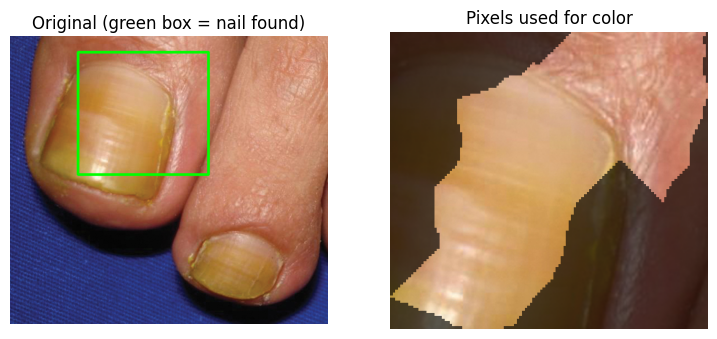

In [ ]:
def run_pipeline(image_bytes, name="Uploaded Image"):
    img = np.array(Image.open(io.BytesIO(image_bytes)).convert("RGB"))
    print("=" * 60)
    print(f"NAIL SCREENING REPORT: {name}")
    print("=" * 60)

    def _show():
        y0, y1, x0, x1 = box
        shown = img.copy()
        cv2.rectangle(shown, (x0, y0), (x1, y1), (0, 255, 0), max(2, img.shape[1] // 150))
        dimmed = (roi * 0.35).astype(np.uint8)
        dimmed[mask] = roi[mask]
        fig, ax = plt.subplots(1, 2, figsize=(9, 4))
        ax[0].imshow(shown); ax[0].set_title("Original (green box = nail found)"); ax[0].axis("off")
        ax[1].imshow(dimmed); ax[1].set_title("Pixels used for color"); ax[1].axis("off")
        plt.show()

    # 1. Quality
    q = quality_check(img)
    print(f"Quality -> blur {q['blur_score']:.0f} | glare {q['glare_frac']*100:.1f}% | brightness {q['brightness']:.0f}")
    if not q["accepted"]:
        print("REJECTED:", "; ".join(q["problems"]))
        print("Please retake the photo (sharp focus, no flash, good light).")
        print("RESULT: Photo rejected - retake it.")
        return None

    # 2. Find nail
    roi, mask, box, found = get_nail_roi(img)
    if not found:
        print("WARNING: could not locate the nail automatically; used the center of the photo.")
        print("         Check the preview below. If it is wrong, set MANUAL_ROI in Step 6.")

    # 3. Cosmetics (nail pixels only)
    c = cosmetic_check(roi, mask)
    if c["suspected"]:
        print("WARNING: possible nail polish / mehendi -> " + "; ".join(c["reasons"]))
        print("Result may be unreliable. Please use a bare nail.")

    # 4. Features
    f = extract_features(roi, mask)
    print(f"Mean RGB: ({f['R']:.0f}, {f['G']:.0f}, {f['B']:.0f}) | HSV: ({f['H']:.0f}, {f['S']:.0f}, {f['V']:.0f}) | LAB: ({f['L']:.0f}, {f['a']:.0f}, {f['b']:.0f})")

    if c["suspected"] and SKIP_ON_COSMETIC:
        print("-" * 60)
        print("SCREENING SKIPPED: polish / mehendi makes the nail color unreliable.")
        print("Please retake the photo with a bare nail.")
        print("RESULT: Cannot screen (polish/mehendi on nail) - retake with a bare nail.")
        _show()
        return f

    # 5. Screening
    flags = screen(f)
    print("-" * 60)
    if not flags:
        print("No color-based flags. Nail color looks within the expected range.")
    for title, meaning, tests in flags:
        print(f"FLAG: {title}\n   {meaning}\n   {tests}")
    print("-" * 60)
    print("Note: screening aid only, not a diagnosis. Consult a doctor for confirmatory tests.")

    SHORT = {"Pale nails": "anemia / low hemoglobin",
             "Yellowish nails": "diabetes / cholesterol / liver issue",
             "Bluish tint": "low oxygen (heart/lung)"}
    if flags:
        print("RESULT: Possible risk of " + "; ".join(SHORT.get(t, t) for t, _, _ in flags) + ". Confirm with blood tests.")
    else:
        print("RESULT: No color-based risk detected (this does not guarantee good health).")

    _show()
    return f

if IN_COLAB:
    from google.colab import files
    print("Upload a nail photo:")
    up = files.upload()
    feature_rows = []
    for fname, content in up.items():
        feats = run_pipeline(content, fname)
        if feats: feature_rows.append({"file": fname, **feats})


### Step 11 (next stage): replace rules with a trained model
Once you have a dataset of nail photos with confirmed labels (e.g., from blood reports), save the features from Step 8 into a CSV with a `label` column (`normal`, `anemia`, `diabetes`, ...) and train a classifier. Thresholds then stop being guesses.

In [ ]:
# Run this only when you have a labeled CSV (columns = features from Step 8 + 'label')
# from sklearn.ensemble import RandomForestClassifier
# from sklearn.model_selection import train_test_split
# from sklearn.metrics import classification_report
#
# df = pd.read_csv("nail_features_labeled.csv")
# X = df.drop(columns=["label", "file"], errors="ignore")
# y = df["label"]
# Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
# model = RandomForestClassifier(n_estimators=300, random_state=42).fit(Xtr, ytr)
# print(classification_report(yte, model.predict(Xte)))
